## 🧪 - Experiment setup
- `fwd`: Forward Solution
- `con`: Structural Connectivity
- `eeg`: EEG template
- `parc`: Parcellation
- `ras2tkras`: subject to freesurfer transform

In [1]:
import mindmap as mm
import numpy as np
import mne

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
fwd = dm.load(sub, "fwd", desc="sim")
con = dm.load(sub, "con")
eeg = dm.load(sub, "ave-temp")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")


## 🧬 - Data Processing

Build simulation.

In [2]:
# signal for source
spike = mm.analysis.simulation.SpikeSignal(
    width = 0.1,
    onset = 0.5,
    repeat = 1,
    scale = 1e-8,
    event_id = 1,
)

# source (signal + location)
source = mm.analysis.simulation.Source(
    locations = ["ctx-rh-lateralorbitofrontal_3"],
    signal = spike,
)

# head model
head_model = mm.analysis.simulation.HeadModel(
    sensors = eeg,
    forward = fwd,
    connectivity_weights = con > 0,
    connectivity_lengths = con,
    parcellation = parc,
    ras2tkras = ras2tkras,
)


# Epoch configuration
epoch_config = mm.analysis.simulation.EpochConfig(
    tmin = -0.45,
    tmax = 0.45,
    baseline = (-0.45, -0.2),
    signal_window = (-0.1, 0.45),
)

# Propagation configuration
prop_config = mm.analysis.simulation.PropagationConfig(
    conduction_speed = 30,
    nodal_delay = 10,
    spatial_decay = 0.5,
    jitter = 1,
)

sim = mm.analysis.simulation.Simulator(head_model, epoch_config)

Run simulation.

In [3]:
gold, raw = sim.run(source, prop_config, snr_target = 10)

## 📊 - Visualization
Spike Waveforms

<Axes: title={'center': 'Waveform: Spike'}, xlabel='Time [s]', ylabel='Dipole activity [A]'>

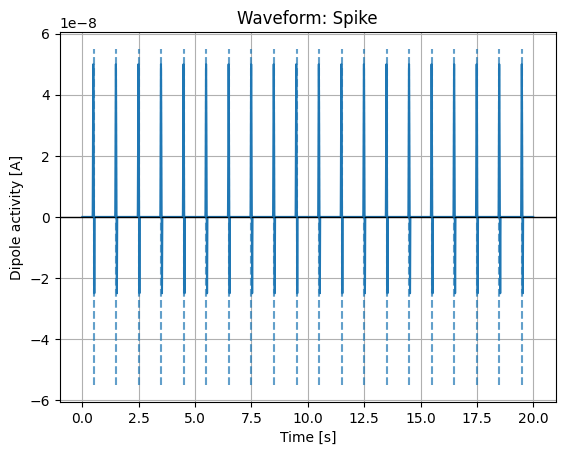

In [4]:
mm.viz.plot_signal(eeg.times, spike, show_events=True)

Source

In [5]:
mm.viz.plot_source(sim.hm, source).show()

Widget(value='<iframe src="http://localhost:33507/index.html?ui=P_0x7005491a8250_0&reconnect=auto" class="pyvi…

Gold standard.

In [6]:
mm.viz.plot_brain_activity(fwd["src"], gold).show()

Widget(value='<iframe src="http://localhost:33507/index.html?ui=P_0x70054721fe90_1&reconnect=auto" class="pyvi…

Recordings.

Maximum single trial SNR: 10.279773369144023


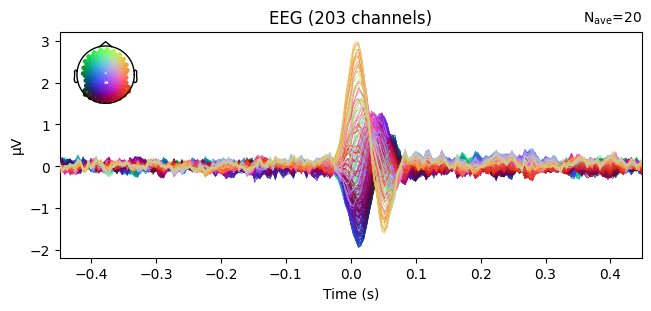

In [7]:
events = mne.events_from_annotations(raw, verbose="warning")[0]

snrs = mm.analysis.eeg.estimate_raw_snr(
    raw, 
    events,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    signal_window = epoch_config.signal_window,
)

print(f"Maximum single trial SNR: {snrs.max()}")

epochs = mne.Epochs(
    raw,
    events,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    verbose = "warning",
)

ave = epochs.average()

ave.plot();

## - Bonus
Generate a dataset containing simulations.

In [ ]:
brain_regions = parc.clut["Label name"]
sources = [mm.analysis.simulation.Source(br, spike) for br in brain_regions]

mm.analysis.simulation.generate_simulation_dataset(
    dm = dm,
    subject = "simf10",
    simulator = sim,
    sources = sources,
    prop_config = prop_config,
    repetitions = 1,
    snr_targets = [10]
)

## 🎯 - Noise/SNR sweep dataset

Second dataset: a noise/SNR sweep restricted to a small, spatially uniform subset of
cortical regions (rather than every parcellation region). See
`simulation_spike_noise_dataset_plan.md` next to this notebook for the full plan.

### Step 1 - Select representative brain regions

Regions are picked via greedy farthest-point sampling (Euclidean distance) over
cortical region centroids, so the selection is spread across lobes and hemispheres
instead of being biased by region size or naming order.

In [9]:
n_regions = 8

representative_regions = mm.anatomy.parcellation.select_uniform_regions(
    source_space = fwd["src"],
    parcellation = parc,
    ras2tkras = ras2tkras,
    n_regions = n_regions,
    seed = 0,
)

representative_regions

['ctx-rh-rostralanteriorcingulate_1',
 'ctx-lh-lateraloccipital_1',
 'ctx-lh-middletemporal_3',
 'ctx-rh-supramarginal_4',
 'ctx-lh-precentral_16',
 'ctx-rh-inferiortemporal_2',
 'ctx-lh-rostralmiddlefrontal_4',
 'ctx-rh-caudalmiddlefrontal_3']

In [9]:
dipole_labels = mm.analysis.connectivity.get_dipole_region_labels(fwd["src"], parc, ras2tkras, return_id=False)
region_mask = np.isin(dipole_labels, representative_regions).astype(float)

mm.viz.plot_brain_activity(fwd["src"], region_mask).show()

Widget(value='<iframe src="http://localhost:42127/index.html?ui=P_0x76efd1a30e10_2&reconnect=auto" class="pyvi…

### Step 2 - Generate the sweep dataset

Sweep six finite SNR levels plus a noise-only condition, across the regions selected
above, all landing in one dataset (`sub-simf10-noisesweep`).

In [10]:
sources = [mm.analysis.simulation.Source(r, spike) for r in representative_regions]

mm.analysis.simulation.generate_simulation_dataset(
    dm = dm,
    subject = "simf10-noisesweep",
    simulator = sim,
    sources = sources,
    prop_config = prop_config,
    repetitions = 5,
    snr_targets = [50, 20, 10, 5, 2, 1, None],
    n_jobs = 4,
)

sub-simf10-noisesweep: 100%|██████████| 245/245 [06:53<00:00,  1.69s/it]


Successfully generated dataset for sub-simf10-noisesweep. Total runs compiled: 245


In [12]:
dm.subjects

['intra12', 'intra48', 'simf10', 'spike11', 'vep10']